# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_1458.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')

In [6]:
data.to_csv('results/SATReset_1458.csv', index = False)

In [7]:
data['result'] = data['info'].str.split(';').str[0].where(data.solved, 'Unsolved')

In [8]:
data.head()

,problem,strategy,status,solved,steps,time_ms,info,error,result
0,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
1,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
2,AGT002+2.p,SATResetAtStaleAction,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleAct...,NaN,Theorem (SAT)
3,AGT002+2.p,SATResetAtStaleBacktrack,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleBac...,NaN,Theorem (SAT)
4,AGT002+2.p,SATResetBandit,solved,True,0.0,0.0,"Theorem (SAT); reset=policy:SATResetBandit,cut...",NaN,Theorem (SAT)


In [9]:
pandas.crosstab(
    data.strategy,
    data.result,
)

result,Theorem,Theorem (SAT),Unsolved
strategy,,,
FirstAction,70,0,1290
LeanCopCut,178,0,1182
SATResetAtStaleAction,0,276,1084
SATResetAtStaleBacktrack,0,277,1083
SATResetAtTwo,0,279,1081
SATResetBandit,0,255,1105
SATResetStart,0,272,1088
SATSolve,0,159,1201
SATSolveLiteral,0,243,1117


In [35]:
problems[1::2]

problem
ALG    315
BIO      9
CAT    117
COM     81
FLD    144
GRA     36
HAL     27
HWC      9
KLE    207
LAT    540
LDA     45
MGT    126
NLP    522
NUN      9
PLA     72
PUZ    117
RNG    207
SCT    171
SEU    738
SWB     99
SWV    828
SYN    981
TOP    117
Name: count, dtype: int64

In [43]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
)

,problem,count,problem,count,problem,count
0,AGT,45,ALG,315.0,ANA,72.0
1,BIO,9,BOO,108.0,CAT,117.0
2,COL,198,COM,81.0,CSR,423.0
3,FLD,144,GEO,603.0,GRA,36.0
4,GRP,918,HAL,27.0,HEN,45.0
5,HWC,9,HWV,351.0,KLE,207.0
6,KRS,261,LAT,540.0,LCL,621.0
7,LDA,45,MED,18.0,MGT,126.0
8,MSC,18,NLP,522.0,NUM,738.0
9,NUN,9,PHI,9.0,PLA,72.0


# Analysing

In [13]:
control = ['FirstAction', 'LeanCopCut']

In [14]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error,result
0,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
1,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
2,AGT002+2.p,SATResetAtStaleAction,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleAct...,NaN,Theorem (SAT)
3,AGT002+2.p,SATResetAtStaleBacktrack,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleBac...,NaN,Theorem (SAT)
4,AGT002+2.p,SATResetBandit,solved,True,0.0,0.0,"Theorem (SAT); reset=policy:SATResetBandit,cut...",NaN,Theorem (SAT)
...,...,...,...,...,...,...,...,...,...
12160,SYN971+1.p,FirstAction,solved,True,2.0,0.0,Theorem,NaN,Theorem
12161,SYN971+1.p,LeanCopCut,solved,True,2.0,0.0,Theorem,NaN,Theorem
12162,SYN971+1.p,SATResetAtTwo,solved,True,5.0,0.0,"Theorem (SAT); literal=choices:4,forward:5,uni...",NaN,Theorem (SAT)
12163,SYN971+1.p,SATResetStart,solved,True,5.0,0.0,"Theorem (SAT); literal=choices:4,forward:5,uni...",NaN,Theorem (SAT)


In [15]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                  70
LeanCopCut                  178
SATResetAtStaleAction       276
SATResetAtStaleBacktrack    277
SATResetAtTwo               279
SATResetBandit              255
SATResetStart               272
SATSolve                    159
SATSolveLiteral             243
dtype: int64

# Results

<Axes: xlabel='strategy'>

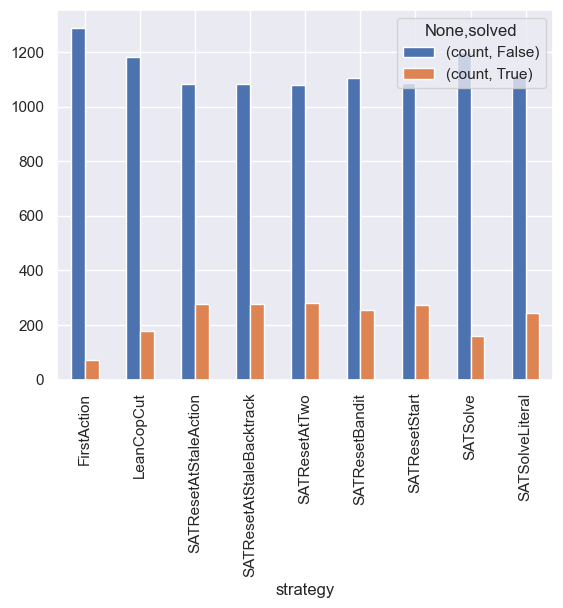

In [16]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [17]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [18]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetAtTwo,SATResetBandit,SATResetStart,SATSolve,SATSolveLiteral
strategy_left,,,,,,,,,
FirstAction,1360,1360,1360,1360,1360,1360,1360,1360,1360
LeanCopCut,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleAction,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleBacktrack,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtTwo,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetBandit,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetStart,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATSolve,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATSolveLiteral,1360,1360,1360,1360,1360,1360,1360,1360,1360


In [48]:
results

strategy_left             strategy_right          
FirstAction               SATResetAtTwo               220
                          SATResetAtStaleBacktrack    218
                          SATResetAtStaleAction       217
                          SATResetStart               213
                          SATResetBandit              197
                                                     ... 
SATResetStart             SATSolve                      4
SATResetAtTwo             SATSolve                      3
SATResetAtStaleBacktrack  SATSolve                      2
SATResetAtStaleAction     SATSolve                      2
                          SATResetAtStaleBacktrack      1
Name: count, Length: 70, dtype: int64

In [55]:
level

strategy_right
FirstAction                  97
SATSolve                    146
LeanCopCut                  260
SATSolveLiteral             463
SATResetBandit              473
SATResetStart               565
SATResetAtStaleAction       568
SATResetAtStaleBacktrack    574
SATResetAtTwo               604
Name: count, dtype: int64

In [54]:
level = results.groupby(level = 'strategy_right').sum().sort_values()
results.loc[level.index]

strategy_left  strategy_right          
FirstAction    SATResetAtTwo               220
               SATResetAtStaleBacktrack    218
               SATResetAtStaleAction       217
               SATResetStart               213
               SATResetBandit              197
                                          ... 
SATResetAtTwo  LeanCopCut                   16
               SATResetAtStaleAction        15
               FirstAction                  11
               SATResetBandit                7
               SATSolve                      3
Name: count, Length: 70, dtype: int64

In [64]:
values.groupby(level = 'strategy_right').sum().sort_values().index

Index(['FirstAction', 'SATSolve', 'LeanCopCut', 'SATSolveLiteral',
       'SATResetBandit', 'SATResetStart', 'SATResetAtStaleAction',
       'SATResetAtStaleBacktrack', 'SATResetAtTwo'],
      dtype='object', name='strategy_right')

In [65]:
values.loc[values.groupby(level = 'strategy_right').sum().sort_values().index]

strategy_left  strategy_right          
FirstAction    SATResetAtTwo               220
               SATResetAtStaleBacktrack    218
               SATResetAtStaleAction       217
               SATResetStart               213
               SATResetBandit              197
                                          ... 
SATResetAtTwo  LeanCopCut                   16
               SATResetAtStaleAction        15
               FirstAction                  11
               SATResetBandit                7
               SATSolve                      3
Name: count, Length: 70, dtype: int64

<Axes: xlabel='Winner', ylabel='Loser'>

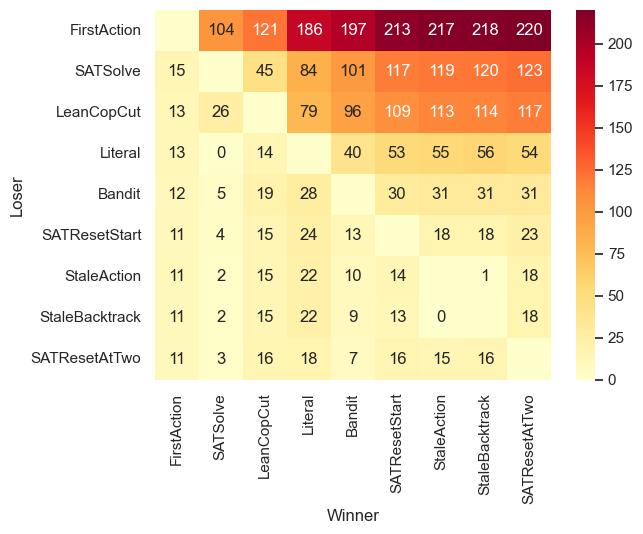

In [66]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATSolve',
    'SATSolveLiteral': 'Literal',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

# Analysis

In [20]:
merged[~merged.solved_left & merged.solved_right].loc[lambda x: (x.strategy_left == 'SATResetAtStaleAction') & (x.strategy_right == 'SATResetAtStaleBacktrack')]

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,result_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,result_right
31296,NUM508+3.p,SATResetAtStaleAction,timeout,False,5158.0,120010.0,"score=1.0; literal=choices:4460,forward:592870...",NaN,Unsolved,SATResetAtStaleBacktrack,solved,True,5345.0,111125.0,Theorem (SAT); score=1.0; literal=choices:4626...,NaN,Theorem (SAT)


In [21]:
data.groupby('strategy').result.value_counts()

strategy                  result       
FirstAction               Unsolved         1290
                          Theorem            70
LeanCopCut                Unsolved         1182
                          Theorem           178
SATResetAtStaleAction     Unsolved         1084
                          Theorem (SAT)     276
SATResetAtStaleBacktrack  Unsolved         1083
                          Theorem (SAT)     277
SATResetAtTwo             Unsolved         1081
                          Theorem (SAT)     279
SATResetBandit            Unsolved         1105
                          Theorem (SAT)     255
SATResetStart             Unsolved         1088
                          Theorem (SAT)     272
SATSolve                  Unsolved         1201
                          Theorem (SAT)     159
SATSolveLiteral           Unsolved         1117
                          Theorem (SAT)     243
Name: count, dtype: int64

In [22]:
data[(data.strategy == 'LeanCopCut') & (data['info'].str.startswith('Theorem (SAT)'))]

,problem,strategy,status,solved,steps,time_ms,info,error,result
